# Análise e Caracterização do Dataset

In [5]:
%pip install --upgrade kaleido

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.0 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 1. Análise Descritiva e Estatística das Anotações

In [6]:
import pandas as pd

classes = ["BlackRot", "Esca", "LeafBlight"]

analise_descritiva_df = pd.DataFrame([], columns=["Número de Imagens",
                                                "Número de objetos (Media)",
                                                  "Número de objetos (Mediana)",
                                                  "Número de objetos (Desvio Padrão)",
                                                  "Total de anotações por classe",
                                                  "Média da área das caixas",
                                                  "Mediana da área das caixas",
                                                  "Desvio Padrão da área das caixas",
                                                  "Q1 da área das caixas",
                                                  "Q3 da área das caixas",
                                                  "IQR da área das caixas",
                                                  "Upper Fence dos Outliers (1.2)",
                                                  "Lower Fence dos Outliers (1.2)",
                                                  "Número de anotações Outliers (1.2)",
                                                  "Upper Fence dos Outliers (1.5)",
                                                  "Lower Fence dos Outliers (1.5)",
                                                  "Número de anotações Outliers (1.5)",
                                                  "Média de porpoções das bounding boxes em relação à imagem (%)",
                                                  "Mediana de porpoções das bounding boxes em relação à imagem (%)",
                                                  "Desvio Padrão de porpoções das bounding boxes em relação à imagem (%)"
                                                  ],
                                                  index=classes)

### A. Número de Imagens

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from PIL import Image
from PIL.ImageOps import grayscale
import cv2
import os

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# File Paths
main_path = "OriginalDataCVAT/images"

test_path = "/test"
train_path = "/train"

black_rot_path = main_path + test_path + "/BlackRot"
esca_path = main_path + test_path + "/Esca"
leaf_blight_path = main_path + test_path + "/LeafBlight"

# Labels Encodings
enconded_labels_info = {
    'BlackRot' : 0,
    'Esca' : 1,
    'LeafBlight' : 2
}

# Lists for data
images = [[], [], []]
paths = [[], [], []]

# Image Resolution
num_pixels = 19
image_shape = (num_pixels, num_pixels)

for label in ['BlackRot', 'Esca', 'LeafBlight']:
    if label == 'BlackRot':
        path_label = black_rot_path
    elif label == 'Esca':
        path_label = esca_path
    elif label == 'LeafBlight':
        path_label = leaf_blight_path
    
    for path in os.listdir(path_label):
        
        #Open image and convert to GrayScale, with the sized from histogram
        img = path_label + '/' + path
        #img = Image.open(path_label + '/' + path)
            
        #resize
        #img = img.resize(image_shape)

        #convert and turn 1D
        #img = np.array(img).flatten()

        #Append to Array
        images[enconded_labels_info[label]].append(img)
        paths[enconded_labels_info[label]].append(path)


black_rot_path = main_path + train_path + "/BlackRot"
esca_path = main_path + train_path + "/Esca"
leaf_blight_path = main_path + train_path + "/LeafBlight"


for label in ['BlackRot', 'Esca', 'LeafBlight']:
    if label == 'BlackRot':
        path_label = black_rot_path
    elif label == 'Esca':
        path_label = esca_path
    elif label == 'LeafBlight':
        path_label = leaf_blight_path
    
    for path in os.listdir(path_label):
        
        #Open image and convert to GrayScale, with the sized from histogram
        img = path_label + '/' + path
        img_pil = Image.open(path_label + '/' + path)

        image_area = np.array(img_pil).shape[0] * np.array(img_pil).shape[1]
            
        #resize
        #img = img.resize(image_shape)

        #convert and turn 1D
        #img = np.array(img).flatten()

        #Append to Array
        images[enconded_labels_info[label]].append(img)
        paths[enconded_labels_info[label]].append(path)


display(pd.DataFrame([len(images[i]) for i in range(len(images))], columns=["Número de Imagens"], index=["BlackRot", "Esca", "LeafBlight"]).T)

,BlackRot,Esca,LeafBlight
Número de Imagens,2360,2400,2152


### B. Número de objetos por imagem

In [11]:
import cv2
import matplotlib.pyplot as plt
import os
from PIL import Image
import numpy as np
import pandas as pd


main_path = "OriginalDataCVAT"

black_rot_path_img_train = main_path + "/images/train/BlackRot"
black_rot_path_annot_train = main_path + "/labels/train/BlackRot"

black_rot_path_img_test = main_path + "/images/test/BlackRot"
black_rot_path_annot_test = main_path + "/labels/test/BlackRot"

esca_path_img_train = main_path + "/images/train/Esca"
esca_path_annot_train = main_path + "/labels/train/Esca"

esca_path_img_test = main_path + "/images/test/Esca"
esca_path_annot_test = main_path + "/labels/test/Esca"

leaf_blight_path_img_train = main_path + "/images/train/LeafBlight"
leaf_blight_path_annot_train = main_path + "/labels/train/LeafBlight"

leaf_blight_path_img_test = main_path + "/images/test/LeafBlight"
leaf_blight_path_annot_test = main_path + "/labels/test/LeafBlight"


annot_br = pd.DataFrame([], columns = ["label", "x", "y", "w", "h", "file_name"])
annot_esca = pd.DataFrame([], columns = ["label", "x", "y", "w", "h", "file_name"])
annot_leafbl = pd.DataFrame([], columns = ["label", "x", "y", "w", "h", "file_name"])


###
for file_name in os.listdir(black_rot_path_annot_train):
    annot_temp = pd.read_csv(black_rot_path_annot_train + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_br = pd.concat([annot_br, annot_temp], ignore_index=True)

for file_name in os.listdir(black_rot_path_annot_test):
    annot_temp = pd.read_csv(black_rot_path_annot_test + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_br = pd.concat([annot_br, annot_temp], ignore_index=True)

for file_name in os.listdir(esca_path_annot_train):
    annot_temp = pd.read_csv(esca_path_annot_train + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_esca = pd.concat([annot_esca, annot_temp], ignore_index=True)

for file_name in os.listdir(esca_path_annot_test):
    annot_temp = pd.read_csv(esca_path_annot_test + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_esca = pd.concat([annot_esca, annot_temp], ignore_index=True)

for file_name in os.listdir(leaf_blight_path_annot_train):
    annot_temp = pd.read_csv(leaf_blight_path_annot_train + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_leafbl = pd.concat([annot_leafbl, annot_temp], ignore_index=True)

for file_name in os.listdir(leaf_blight_path_annot_test):
    annot_temp = pd.read_csv(leaf_blight_path_annot_test + "/" + file_name, header=None, sep=" ")
    annot_temp.columns = ["label", "x", "y", "w", "h"]
    annot_temp["file_name"] = file_name
    annot_leafbl = pd.concat([annot_leafbl, annot_temp], ignore_index=True)


###
annot_br["w"] = annot_br["w"].astype(float)
annot_br["h"] = annot_br["h"].astype(float)
annot_br["x"] = (annot_br["x"] - annot_br["w"]/2).astype(float)
annot_br["y"] = (annot_br["y"] - annot_br["h"]/2).astype(float)

annot_esca["w"] = annot_esca["w"].astype(float)
annot_esca["h"] = annot_esca["h"].astype(float)
annot_esca["x"] = (annot_esca["x"] - annot_esca["w"]/2).astype(float)
annot_esca["y"] = (annot_esca["y"] - annot_esca["h"]/2).astype(float)


annot_leafbl["w"] = annot_leafbl["w"].astype(float)
annot_leafbl["h"] = annot_leafbl["h"].astype(float)
annot_leafbl["x"] = (annot_leafbl["x"] - annot_leafbl["w"]/2).astype(float)
annot_leafbl["y"] = (annot_leafbl["y"] - annot_leafbl["h"]/2).astype(float)

annot = pd.concat([annot_br, annot_esca, annot_leafbl], ignore_index=True)

In [ ]:
annot_leafbl[annot_leafbl["label"] != 2]

,label,x,y,w,h,file_name
11936,1,0.234960,0.373125,0.107539,0.087109,626ad08f-81e7-4ae4-8e4a-7b71f16adee9___FAM_L.B...
26155,1,0.394922,0.738438,0.035234,0.040625,ea7391a1-7052-4db6-bbd4-210fb75bd238___FAM_L.B...
26156,1,0.393554,0.088008,0.069102,0.093516,ea7391a1-7052-4db6-bbd4-210fb75bd238___FAM_L.B...
28348,1,0.119844,0.261445,0.176172,0.111133,fe6c78a9-5db7-4cef-afbe-fc3a57a068e0___FAM_L.B...
28354,1,0.725546,0.276367,0.138203,0.092148,fe6c78a9-5db7-4cef-afbe-fc3a57a068e0___FAM_L.B...


In [12]:
def get_obj_per_img(data_pd):

    new_list = []

    last_image = ""
    i = -1

    for index, data in data_pd.iterrows():

        if data["file_name"] != last_image:
            new_list.append(1)
            last_image = data["file_name"]
            i += 1
        else:
            new_list[i] += 1.

    return new_list

list_annot_per_image = [
    get_obj_per_img(annot[annot["label"] == enconded_labels_info["BlackRot"]]),
    get_obj_per_img(annot[annot["label"] == enconded_labels_info["Esca"]]), 
    get_obj_per_img(annot[annot["label"] == enconded_labels_info["LeafBlight"]])
]

In [13]:
import pandas as pd

classes = ["Geral", "BlackRot", "Esca", "LeafBlight"]

analise_descritiva_df = pd.DataFrame([], columns=[#"Número de Imagens",
                                                "Número de objetos (Media)",
                                                  "Número de objetos (Mediana)",
                                                  "Número de objetos (Desvio Padrão)",
                                                  "Total de anotações por classe",
                                                  "Média da área das caixas",
                                                  "Mediana da área das caixas",
                                                  "Desvio Padrão da área das caixas",
                                                  "Q1 da área das caixas",
                                                  "Q3 da área das caixas",
                                                  "IQR da área das caixas",
                                                  "Upper Fence dos Outliers (1.2)",
                                                  "Lower Fence dos Outliers (1.2)",
                                                  "Número de anotações Outliers (1.2)",
                                                  "Upper Fence dos Outliers (1.5)",
                                                  "Lower Fence dos Outliers (1.5)",
                                                  "Número de anotações Outliers (1.5)",
                                                  "Média de porpoções das bounding boxes em relação à imagem (%)",
                                                  "Mediana de porpoções das bounding boxes em relação à imagem (%)",
                                                  "Desvio Padrão de porpoções das bounding boxes em relação à imagem (%)"
                                                  ],
                                                  index=classes)

In [14]:
# Original Image Shape
original_image_width, original_image_height = 256, 256


# Loop through index/classes
cl_int = 0
for cl in classes: 

    if cl == "Geral":
        # Auxiliar Variables
        area_numpy = np.array((annot["w"] * original_image_width) * (annot["h"] * original_image_height))


        #analise_descritiva_df["Número de Imagens"] = [len(images[i]) for i in range(len(images))]

        # Number of objects per image (Average)
        analise_descritiva_df["Número de objetos (Media)"][cl] = np.average(get_obj_per_img(annot))
        analise_descritiva_df["Número de objetos (Mediana)"][cl] = np.median(get_obj_per_img(annot))
        analise_descritiva_df["Número de objetos (Desvio Padrão)"][cl] = np.std(get_obj_per_img(annot))

        # Number of objects per image (Average)
        #analise_descritiva_df["Número de objetos (Media)"][cl] = annot[annot["label"] == cl_int].shape[0] / (len(images[cl_int]))
        #print(annot[annot["label"] == cl_int].shape[0] / (len(images[cl_int])))
        analise_descritiva_df["Total de anotações por classe"][cl] = annot.shape[0]

        # Average, Mean and Standart Deviation of the box area
        analise_descritiva_df["Média da área das caixas"][cl] = np.average(area_numpy)
        analise_descritiva_df["Mediana da área das caixas"][cl] = np.median(area_numpy)
        analise_descritiva_df["Desvio Padrão da área das caixas"][cl] = np.std(area_numpy)
        
        

        # Q1, Q3, IQR
        Q1 = analise_descritiva_df["Q1 da área das caixas"][cl] = np.quantile(area_numpy, 0.25)
        Q3 = analise_descritiva_df["Q3 da área das caixas"][cl] = np.quantile(area_numpy, 0.75)
        IQR = analise_descritiva_df["IQR da área das caixas"][cl] = Q3 - Q1

        # Upper/Lower Fence of the Outliers (1.2)
        lower_fence = analise_descritiva_df["Lower Fence dos Outliers (1.2)"][cl] = max([Q1 - 1.2 * IQR, min(area_numpy)])     ###Verificar
        upper_fence = analise_descritiva_df["Upper Fence dos Outliers (1.2)"][cl] = min([Q3 + 1.2 * IQR, max(area_numpy)])

        # Number of outliers (1.2)
        analise_descritiva_df["Número de anotações Outliers (1.2)"][cl] = len([outlier for outlier in area_numpy if outlier > upper_fence or outlier < lower_fence])

        # Upper/Lower Fence of the Outliers (1.5)
        lower_fence = analise_descritiva_df["Lower Fence dos Outliers (1.5)"][cl] = max([Q1 - 1.5 * IQR, min(area_numpy)])
        upper_fence = analise_descritiva_df["Upper Fence dos Outliers (1.5)"][cl] = min([Q3 + 1.5 * IQR, max(area_numpy)])

        # Number of outliers (1.5)
        analise_descritiva_df["Número de anotações Outliers (1.5)"][cl] = len([outlier for outlier in area_numpy if outlier > upper_fence or outlier < lower_fence])

        # Average, Median and Standart Deviation of the scale of the box to the image
        scale = area_numpy / image_area * 100
        analise_descritiva_df["Média de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.average(scale)
        analise_descritiva_df["Mediana de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.median(scale)
        analise_descritiva_df["Desvio Padrão de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.std(scale)


    else:
        # Auxiliar Variables
        area_numpy = np.array((annot[annot["label"] == cl_int]["w"] * original_image_width) * (annot[annot["label"] == cl_int]["h"] * original_image_height))


        #analise_descritiva_df["Número de Imagens"] = [len(images[i]) for i in range(len(images))]

        # Number of objects per image (Average)
        analise_descritiva_df["Número de objetos (Media)"][cl] = np.average(list_annot_per_image[cl_int])
        analise_descritiva_df["Número de objetos (Mediana)"][cl] = np.median(list_annot_per_image[cl_int])
        analise_descritiva_df["Número de objetos (Desvio Padrão)"][cl] = np.std(list_annot_per_image[cl_int])

        # Number of objects per image (Average)
        #analise_descritiva_df["Número de objetos (Media)"][cl] = annot[annot["label"] == cl_int].shape[0] / (len(images[cl_int]))
        #print(annot[annot["label"] == cl_int].shape[0] / (len(images[cl_int])))
        analise_descritiva_df["Total de anotações por classe"][cl] = annot[annot["label"] == cl_int].shape[0]

        # Average, Mean and Standart Deviation of the box area
        analise_descritiva_df["Média da área das caixas"][cl] = np.average(area_numpy)
        analise_descritiva_df["Mediana da área das caixas"][cl] = np.median(area_numpy)
        analise_descritiva_df["Desvio Padrão da área das caixas"][cl] = np.std(area_numpy)
        
        

        # Q1, Q3, IQR
        Q1 = analise_descritiva_df["Q1 da área das caixas"][cl] = np.quantile(area_numpy, 0.25)
        Q3 = analise_descritiva_df["Q3 da área das caixas"][cl] = np.quantile(area_numpy, 0.75)
        IQR = analise_descritiva_df["IQR da área das caixas"][cl] = Q3 - Q1


        # Upper/Lower Fence of the Outliers (1.2)
        lower_fence = analise_descritiva_df["Lower Fence dos Outliers (1.2)"][cl] = max([Q1 - 1.2 * IQR, min(area_numpy)])     ###Verificar
        upper_fence = analise_descritiva_df["Upper Fence dos Outliers (1.2)"][cl] = min([Q3 + 1.2 * IQR, max(area_numpy)])

        # Number of outliers (1.2)
        analise_descritiva_df["Número de anotações Outliers (1.2)"][cl] = len([outlier for outlier in area_numpy if outlier > upper_fence or outlier < lower_fence])

        # Upper/Lower Fence of the Outliers (1.5)
        lower_fence = analise_descritiva_df["Lower Fence dos Outliers (1.5)"][cl] = max([Q1 - 1.5 * IQR, min(area_numpy)])
        upper_fence = analise_descritiva_df["Upper Fence dos Outliers (1.5)"][cl] = min([Q3 + 1.5 * IQR, max(area_numpy)])

        # Number of outliers (1.5)
        analise_descritiva_df["Número de anotações Outliers (1.5)"][cl] = len([outlier for outlier in area_numpy if outlier > upper_fence or outlier < lower_fence])

        # Average, Median and Standart Deviation of the scale of the box to the image
        scale = area_numpy / image_area * 100
        analise_descritiva_df["Média de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.average(scale)
        analise_descritiva_df["Mediana de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.median(scale)
        analise_descritiva_df["Desvio Padrão de porpoções das bounding boxes em relação à imagem (%)"][cl] = np.std(scale)


        #   Q1 e Q3 e IQR

        """
        "Upper Fence dos Outliers (1.2)",
        "Lower Fence dos Outliers (1.2)",
        "Número de anotações Outliers (1.2)",
        "Upper Fence dos Outliers (1.5)",
        "Lower Fence dos Outliers (1.5)",
        "Número de anotações Outliers (1.5)",
                                                    
                                                    
                                                    """


        cl_int+=1


display(analise_descritiva_df)

,Número de objetos (Media),Número de objetos (Mediana),Número de objetos (Desvio Padrão),Total de anotações por classe,Média da área das caixas,Mediana da área das caixas,Desvio Padrão da área das caixas,Q1 da área das caixas,Q3 da área das caixas,IQR da área das caixas,Upper Fence dos Outliers (1.2),Lower Fence dos Outliers (1.2),Número de anotações Outliers (1.2),Upper Fence dos Outliers (1.5),Lower Fence dos Outliers (1.5),Número de anotações Outliers (1.5),Média de porpoções das bounding boxes em relação à imagem (%),Mediana de porpoções das bounding boxes em relação à imagem (%),Desvio Padrão de porpoções das bounding boxes em relação à imagem (%)
Geral,12.256366,11.0,7.916682,84716,568.550959,397.053163,593.367984,238.558549,684.745276,446.186727,1220.169348,14.302864,7486,1354.025366,14.302864,5949,0.86754,0.605855,0.905408
BlackRot,8.07287,7.0,5.746475,21603,586.385126,451.322487,475.277352,272.173455,753.87816,481.704705,1331.923805,14.302864,1448,1476.435217,14.302864,1046,0.894753,0.688663,0.725216
Esca,12.333889,11.0,6.340602,29589,709.75135,499.16052,671.769314,308.447478,858.050232,549.602755,1517.573538,51.999867,2661,1682.454364,51.999867,2113,1.082995,0.761659,1.025039
LeafBlight,15.563603,13.0,9.723374,33524,432.432062,295.896627,556.355059,182.550583,495.813099,313.262517,871.728119,16.717448,3031,965.706874,16.717448,2480,0.659839,0.451502,0.84893


# 2. Visualização Estátistica

### A. Histograma das areas das bounding box

<b>Notas:</b>

Intervalo dos Bins: 500

In [ ]:
from matplotlib.pyplot import figure
import matplotlib.pyplot as plt


# Auxiliar Variables
cl_int = 0
area_df = pd.DataFrame([], columns=["Area", "Label"]) 
for cl in classes: 

    if cl == "Geral":
        continue

    area_numpy = np.array((annot[annot["label"] == cl_int]["w"] * original_image_width) * (annot[annot["label"] == cl_int]["h"] * original_image_height))
    new_area_df = pd.DataFrame({"Area" : area_numpy, "Label" : np.array([cl for area in area_numpy])})

    area_df = pd.concat([area_df, new_area_df], axis=0)
    cl_int +=1

#======================
def draw_histogram_abs(X1, X2, X3, bin_interval, label, labelX1, labelX2, labelX3):
    # Set a size to the figure (Better Visibility)
    figure(figsize=(20, 10), dpi=80)

    # Create histogram
    fig, ax = plt.subplots(1, 3, figsize=(30, 5))

    i = 0
    for X, labels in zip([X1, X2, X3], [labelX1, labelX2, labelX3]):
        counts, bins, patches = ax[i].hist(X, bins=int(max(X)/bin_interval), range = (0, max(X)), color='skyblue', edgecolor='black')

        ax[i].set_xlabel("Values of the " + str(labels) + " " + str(label))
        ax[i].set_ylabel("Frequency of the " + str(labels) + " " + str(label))

        # Annotate each bin with its frequency
        for count, x in zip(counts, bins):
            # Calculate the position for the text
            height = count
            # Center the label text into middle of bin
            fig_x_axis = x + (bins[1] - bins[0]) / 2
            ax[i].text(fig_x_axis, height, str(int(count)), ha='center', va='bottom', rotation=45)

        i+=1

    plt.subplots_adjust(wspace=0.5)

    plt.show()



def draw_histogram_perc(X1, X2, X3, bin_interval, label, labelX1, labelX2, labelX3):
    # Set a size to the figure (Better Visibility)
    figure(figsize=(25, 10), dpi=80)


    # Create histogram
    fig, ax = plt.subplots(1, 3, figsize=(30, 5))

    i = 0
    for X, labels in zip([X1, X2, X3], [labelX1, labelX2, labelX3]):
        
        # Create histogram
        counts, bins, patches = ax[i].hist(X, bins=int(max(X)/bin_interval), range = (0, max(X)), weights=np.ones(len(X)) / len(X), color='skyblue', edgecolor='black')

        ax[i].set_xlabel("Values of the " + str(labels) + " " + str(label))
        ax[i].set_ylabel("Frequency of the " + str(labels) + " " + str(label))

    
        # Annotate each bin with its frequency
        for count, x in zip(counts, bins):
            # Calculate the position for the text
            height = count

            # Reverse the weights
            count *= len(X)

            # Center the label text into middle of bin
            fig_x_axis = x + (bins[1] - bins[0]) / 2
            ax[i].text(fig_x_axis, height, str(round(int(count) / len(X) * 100, 2)) + "%", ha='center', va='bottom', rotation=45)

        i+=1

    plt.subplots_adjust(wspace=0.5)

    plt.show()

#=================================000

<Figure size 1600x800 with 0 Axes>

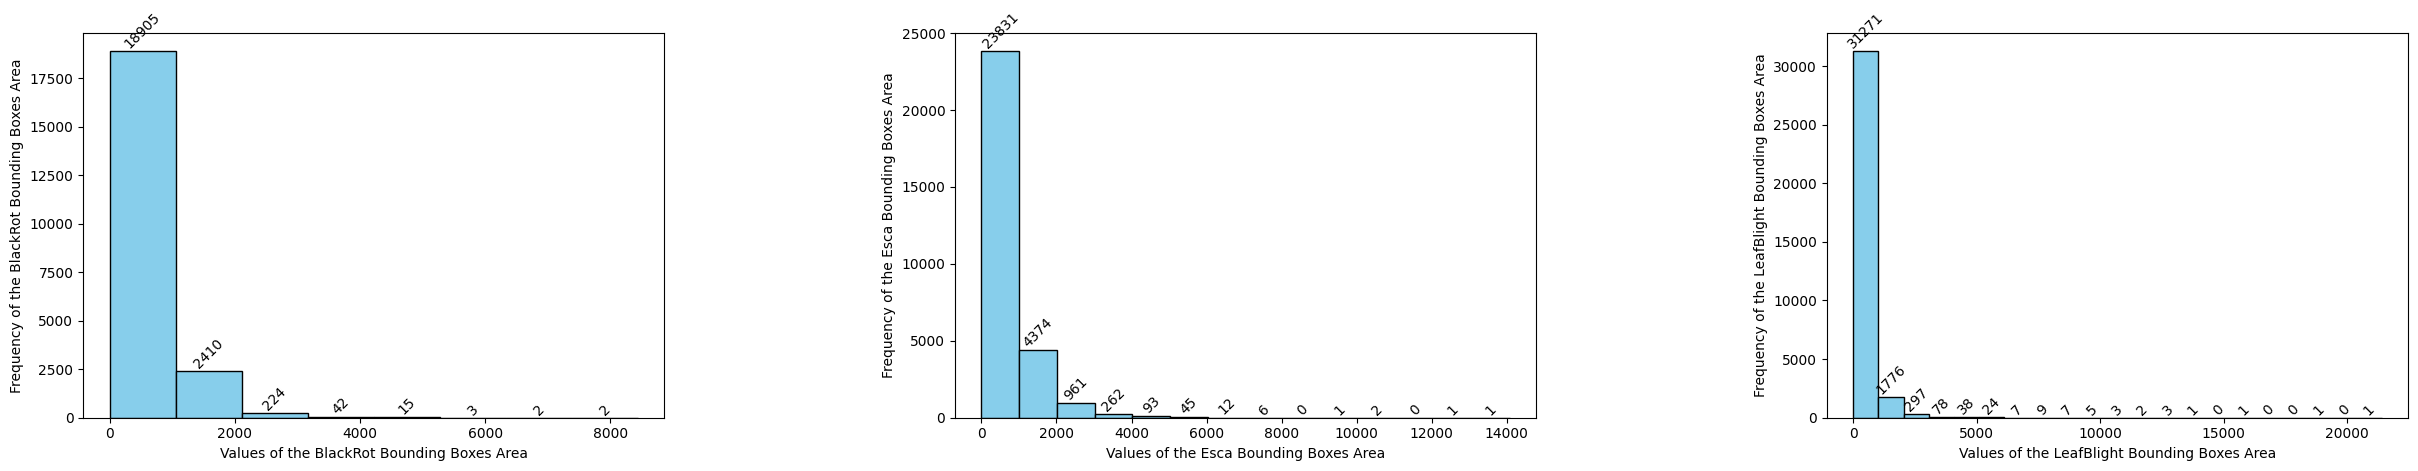

In [ ]:
draw_histogram_abs(area_df[area_df["Label"] == "BlackRot"]["Area"], area_df[area_df["Label"] == "Esca"]["Area"], area_df[area_df["Label"] == "LeafBlight"]["Area"], 1000, "Bounding Boxes Area", "BlackRot", "Esca", "LeafBlight")

<Figure size 2000x800 with 0 Axes>

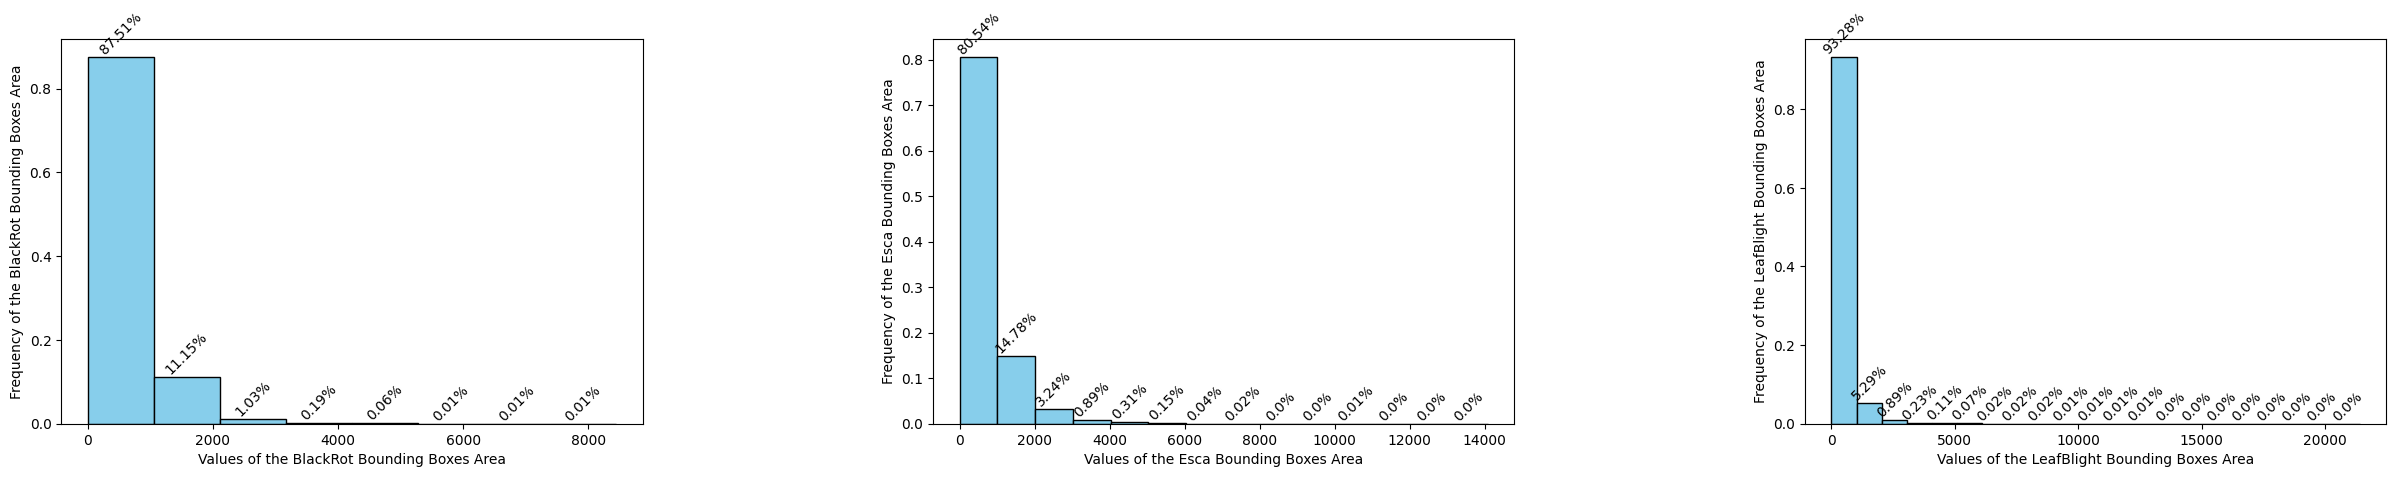

In [ ]:
draw_histogram_perc(area_df[area_df["Label"] == "BlackRot"]["Area"], area_df[area_df["Label"] == "Esca"]["Area"], area_df[area_df["Label"] == "LeafBlight"]["Area"], 1000, "Bounding Boxes Area", "BlackRot", "Esca", "LeafBlight")

In [ ]:
area_df[area_df["Area"] > 10000]["Area"].shape

(17,)

### Box Plot para o tamanho por classes

In [ ]:
import plotly.express as px

fig = px.box(area_df, x="Label", y="Area", color="Label")
display(fig)

fig.write_image("fig1.png")

In [ ]:
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

def draw_separate_box_plot(X1, X2, X3, labelX1, labelX2, labelX3):

    fig = make_subplots(rows=1, cols=3, subplot_titles=(labelX1, labelX2, labelX3))

    fig.add_trace(go.Box(y=X1), row=1, col=1)
    fig.add_trace(go.Box(y=X2), row=1, col=2)
    fig.add_trace(go.Box(y=X3), row=1, col=3)
    #fig = px.box(data, x="Area", title=label)
    display(fig)

In [ ]:
draw_separate_box_plot(area_df[area_df["Label"] == "BlackRot"]["Area"], area_df[area_df["Label"] == "Esca"]["Area"], area_df[area_df["Label"] == "LeafBlight"]["Area"], "BlackRot", "Esca", "LeafBlight")

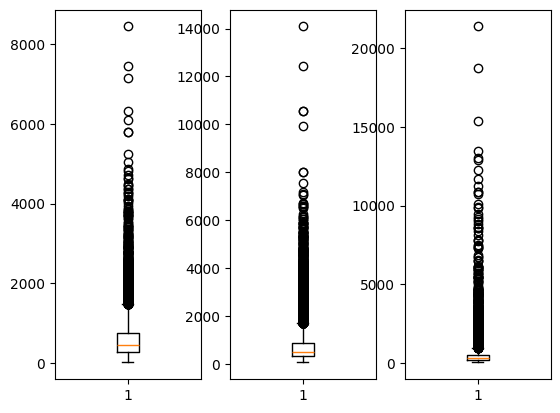

In [ ]:
from matplotlib.pyplot import boxplot

fig, axs = plt.subplots(1, 3)

for ax, label in zip(axs, ["BlackRot", "Esca", "LeafBlight"]):
    ax.boxplot(area_df[area_df["Label"] == label]["Area"], autorange = True, vert = 1, patch_artist = False)

plt.show()